# Analyse Exploratoire — Avantage Domicile en Premier League
**Projet Introduction à Python — 2025/2026**

> Ce notebook présente l'analyse exploratoire de l'avantage domicile en Premier League sur 30 saisons (1993–2023).

---

## 0 — Setup
Chargement des librairies, du dataset et définition de la palette graphique.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import os
from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap
%matplotlib inline

# ── Détection automatique de la racine du projet ──────────────────────
def find_root(target='data/processed/epl_strength.csv', max_levels=6):
    current = Path().resolve()
    for _ in range(max_levels):
        if (current / target).exists():
            return current
        current = current.parent
    raise FileNotFoundError('Fichier non trouvé. Assurez-vous que le notebook est dans le repo.')

ROOT = find_root()
print('✓ Dossier racine :', ROOT)

df = pd.read_csv(ROOT / 'data' / 'processed' / 'epl_strength.csv')
os.makedirs(ROOT / 'outputs' / 'figures', exist_ok=True)
df['AwayWin'] = (df['FTR'] == 'A').astype(int)

# ── Palette fond blanc — couleurs vives et lisibles ───────────────────
C = {
    'home':    '#1a7abf',   # bleu domicile
    'away':    '#e8473f',   # rouge extérieur
    'draw':    '#8c8c8c',   # gris nul
    'covid':   '#f5a623',   # orange Covid
    'purple':  '#7b4fa6',   # violet accent
    'green':   '#2ca85a',   # vert favorable
    'text':    '#1a1a2e',   # texte foncé
    'subtext': '#666680',   # texte secondaire
    'spine':   '#cccccc',   # bordures axes
    'grid':    '#f0f0f0',   # grille légère
}

def white_theme(ax, xlabel=None, ylabel=None):
    '''Applique le thème fond blanc propre à un axe.'''
    ax.set_facecolor('white')
    ax.tick_params(colors=C['text'], labelsize=9)
    if xlabel: ax.set_xlabel(xlabel, color=C['text'], fontsize=10)
    if ylabel: ax.set_ylabel(ylabel, color=C['text'], fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_color(C['spine'])
    ax.spines['left'].set_color(C['spine'])
    ax.grid(False)
    ax.set_axisbelow(True)

def white_legend(ax, **kwargs):
    return ax.legend(facecolor='white', edgecolor=C['spine'],
                     labelcolor=C['text'], fontsize=9, **kwargs)

print('✓ Setup OK — dataset chargé :', df.shape)

✓ Dossier racine : C:\Users\Lara1\Documents\GitHub\epl-home-advantage-analysis-1
✓ Setup OK — dataset chargé : (12026, 16)


## 1 — Distribution de l'échantillon
**Objectif :** vérifier si la variable cible `HomeWin` est équilibrée.

Si le domicile ne jouait aucun rôle, on s'attendrait à ~33% pour chaque issue.

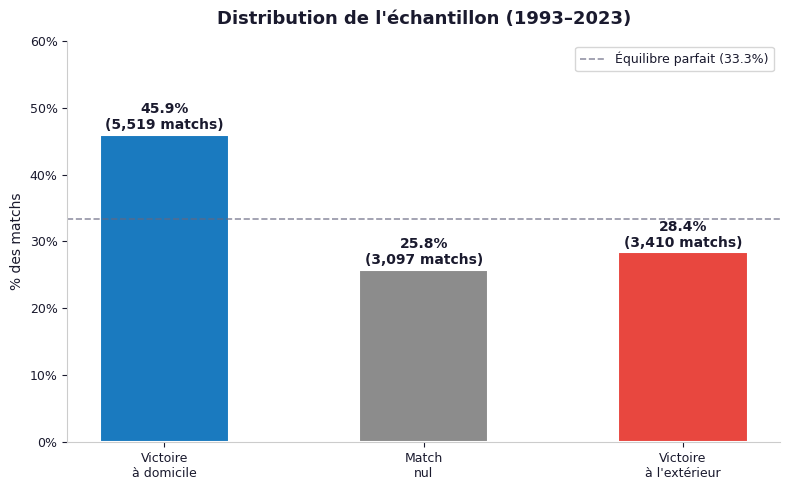

In [10]:
result_counts = df['FTR'].value_counts().reindex(['H', 'D', 'A'])
result_pct    = result_counts / len(df) * 100

labels     = ['Victoire\nà domicile', 'Match\nnul', 'Victoire\nà l\'extérieur']
bar_colors = [C['home'], C['draw'], C['away']]

fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.88, bottom=0.13, left=0.11, right=0.95)

bars = ax.bar(labels, result_pct.values, color=bar_colors,
              width=0.5, edgecolor='white', linewidth=1.5)

# Valeurs au-dessus des barres
for bar, val, count in zip(bars, result_pct.values, result_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
            f'{val:.1f}%\n({count:,} matchs)',
            ha='center', va='bottom', color=C['text'], fontweight='bold', fontsize=10)

# Ligne équilibre parfait
ax.axhline(100/3, color=C['subtext'], linestyle='--', linewidth=1.2, alpha=0.7,
           label='Équilibre parfait (33.3%)')

ax.set_ylabel('% des matchs', color=C['text'], fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 60)
ax.set_title('Distribution de l\'échantillon (1993–2023)',
             fontsize=13, fontweight='bold', color=C['text'], pad=12)
white_theme(ax)
white_legend(ax, loc='upper right')

plt.tight_layout()
plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_01_distribution.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Les victoires à domicile représentent **45,9%** des matchs, soit **12 points au-dessus** de l'équilibre théorique (33,3%). L'échantillon est déséquilibré en faveur du domicile — première indication d'un avantage structurel.

## 2 — Évolution du taux de victoire à domicile par saison
**Objectif :** observer si l'avantage domicile est stable dans le temps.

On met en évidence les saisons Covid (2020–2021), jouées sans public.

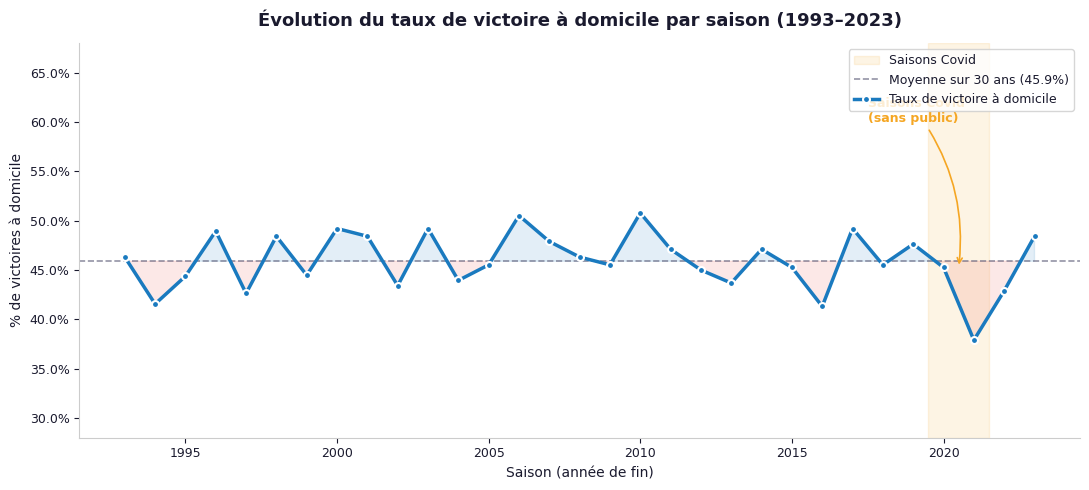

In [11]:
season_stats = df.groupby('Season_End_Year').agg(
    HomeWinRate=('HomeWin', 'mean')
).reset_index()

global_mean = df['HomeWin'].mean() * 100

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.09, right=0.97)

# Zone Covid
ax.axvspan(2019.5, 2021.5, color=C['covid'], alpha=0.12, zorder=0, label='Saisons Covid')

# Remplissage au-dessus / en dessous de la moyenne
ax.fill_between(season_stats['Season_End_Year'],
                season_stats['HomeWinRate']*100, global_mean,
                where=season_stats['HomeWinRate']*100 >= global_mean,
                alpha=0.12, color=C['home'], interpolate=True)
ax.fill_between(season_stats['Season_End_Year'],
                season_stats['HomeWinRate']*100, global_mean,
                where=season_stats['HomeWinRate']*100 < global_mean,
                alpha=0.12, color=C['away'], interpolate=True)

# Ligne moyenne
ax.axhline(global_mean, color=C['subtext'], linestyle='--', linewidth=1.2,
           alpha=0.7, label=f'Moyenne sur 30 ans ({global_mean:.1f}%)')

# Courbe principale
ax.plot(season_stats['Season_End_Year'], season_stats['HomeWinRate']*100,
        color=C['home'], linewidth=2.5, marker='o', markersize=5,
        markerfacecolor=C['home'], markeredgecolor='white', markeredgewidth=1.5,
        label='Taux de victoire à domicile', zorder=5)

# Annotation Covid
ax.annotate('Saisons Covid\n(sans public)',
            xy=(2020.5, season_stats[season_stats['Season_End_Year']==2020]['HomeWinRate'].values[0]*100),
            xytext=(2017.5, 60), color=C['covid'], fontsize=9, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=C['covid'], lw=1.2, connectionstyle='arc3,rad=-0.2'))

ax.set_ylim(28, 68)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Évolution du taux de victoire à domicile par saison (1993–2023)',
             fontsize=13, fontweight='bold', color=C['text'], pad=12)
white_theme(ax, xlabel='Saison (année de fin)', ylabel='% de victoires à domicile')
white_legend(ax, loc='upper right')

plt.tight_layout()
plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_02_evolution_homewin.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Le taux oscille autour de 45–47% sur 30 saisons — l'avantage domicile est **stable et persistant**. La chute pendant le Covid (38% en 2020) et le retour à la normale dès 2022 suggèrent un lien causal avec la présence du public.

## 3 — Impact des saisons Covid
**Objectif :** isoler l'effet de l'absence de public en comparant trois périodes distinctes.

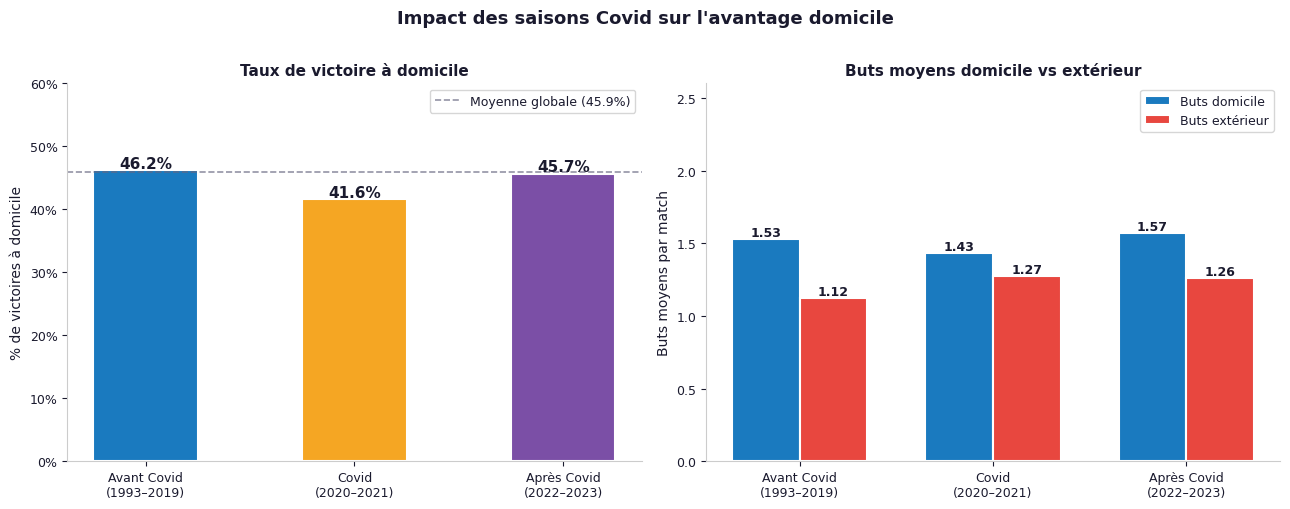

In [12]:
df['Periode'] = pd.cut(df['Season_End_Year'], bins=[1992, 2019, 2021, 2023],
    labels=['Avant Covid\n(1993–2019)', 'Covid\n(2020–2021)', 'Après Covid\n(2022–2023)'])

covid_stats = df.groupby('Periode', observed=True).agg(
    HomeWinRate=('HomeWin', 'mean'),
    AvgHomeGoals=('HomeGoals', 'mean'),
    AvgAwayGoals=('AwayGoals', 'mean'),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.88, bottom=0.13, left=0.07, right=0.97, wspace=0.3)

# ── Sous-graphe gauche : taux de victoire ─────────────────────────────
colors_p = [C['home'], C['covid'], C['purple']]
bars = axes[0].bar(covid_stats['Periode'], covid_stats['HomeWinRate']*100,
                   color=colors_p, width=0.5, edgecolor='white', linewidth=1.5)
for i, (_, row) in enumerate(covid_stats.iterrows()):
    axes[0].text(i, row['HomeWinRate']*100 + 0.4, f"{row['HomeWinRate']*100:.1f}%",
                 ha='center', color=C['text'], fontweight='bold', fontsize=11)
axes[0].axhline(df['HomeWin'].mean()*100, color=C['subtext'], linestyle='--',
                linewidth=1.2, alpha=0.7, label=f"Moyenne globale ({df['HomeWin'].mean()*100:.1f}%)")
axes[0].set_ylim(0, 60)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[0].set_title('Taux de victoire à domicile', fontsize=11, fontweight='bold', color=C['text'])
white_theme(axes[0], ylabel='% de victoires à domicile')
white_legend(axes[0])

# ── Sous-graphe droit : buts moyens ───────────────────────────────────
x = np.arange(len(covid_stats))
w = 0.35
b1 = axes[1].bar(x - w/2, covid_stats['AvgHomeGoals'], w,
                 color=C['home'], label='Buts domicile', edgecolor='white', linewidth=1.5)
b2 = axes[1].bar(x + w/2, covid_stats['AvgAwayGoals'], w,
                 color=C['away'], label='Buts extérieur', edgecolor='white', linewidth=1.5)
for bar in list(b1)+list(b2):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.02,
                 f'{bar.get_height():.2f}', ha='center', color=C['text'],
                 fontweight='bold', fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(covid_stats['Periode'], fontsize=9)
axes[1].set_ylim(0, 2.6)
axes[1].set_title('Buts moyens domicile vs extérieur', fontsize=11, fontweight='bold', color=C['text'])
white_theme(axes[1], ylabel='Buts moyens par match')
white_legend(axes[1])

fig.suptitle('Impact des saisons Covid sur l\'avantage domicile',
             fontsize=13, fontweight='bold', color=C['text'], y=1.01)
plt.tight_layout()
plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_03_effet_covid.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Le taux chute de **46,2% à 41,6%** pendant le Covid, puis remonte à **45,7%** dès le retour du public. Les buts extérieurs augmentent simultanément (1,12 → 1,27). Les deux indicateurs confirment le rôle causal du public.

## 4 — Taux de victoire domicile par quintile de StrengthDiff
**Objectif :** vérifier si l'avantage domicile persiste même quand l'équipe visiteuse est meilleure.

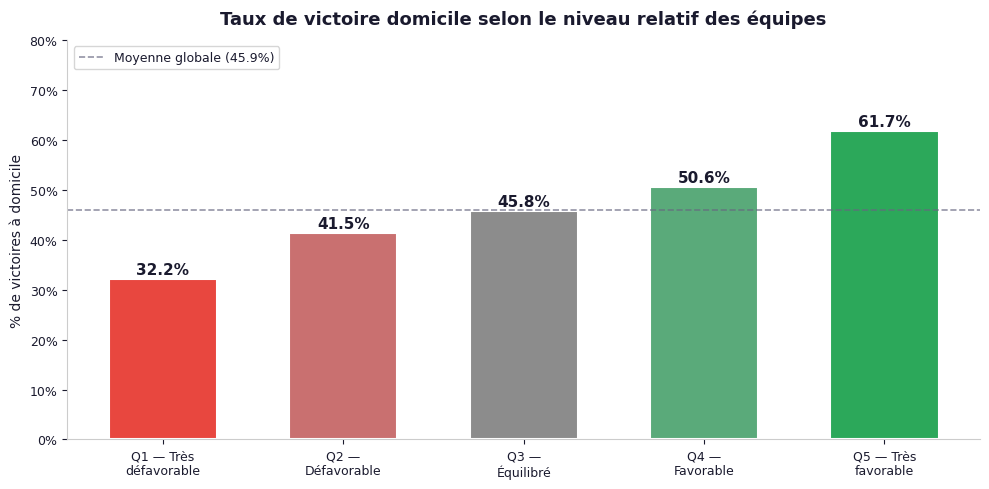

In [13]:
df['StrengthDiff_bin'] = pd.qcut(df['StrengthDiff'], q=5, labels=[
    'Q1 — Très\ndéfavorable', 'Q2 —\nDéfavorable',
    'Q3 —\nÉquilibré',        'Q4 —\nFavorable',
    'Q5 — Très\nfavorable'
])
strength_stats = (df.groupby('StrengthDiff_bin', observed=True)['HomeWin']
                    .agg(['mean','count']).reset_index())
strength_stats.columns = ['Quintile', 'HomeWinRate', 'Count']

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.84, bottom=0.16, left=0.10, right=0.95)

# Dégradé rouge → gris → vert selon le contexte
bar_colors = [C['away'], '#c97070', C['draw'], '#5aaa7a', C['green']]
bars = ax.bar(strength_stats['Quintile'], strength_stats['HomeWinRate']*100,
              color=bar_colors, width=0.6, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, strength_stats['HomeWinRate']):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
            f'{val*100:.1f}%', ha='center', va='bottom',
            color=C['text'], fontweight='bold', fontsize=11)

# Ligne moyenne globale
ax.axhline(df['HomeWin'].mean()*100, color=C['subtext'], linestyle='--',
           linewidth=1.2, alpha=0.7, label=f"Moyenne globale ({df['HomeWin'].mean()*100:.1f}%)")
ax.set_ylim(0, 80)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Taux de victoire domicile selon le niveau relatif des équipes',
             fontsize=13, fontweight='bold', color=C['text'], pad=12)
white_theme(ax, ylabel='% de victoires à domicile')
white_legend(ax, loc='upper left')

plt.tight_layout()
plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_04_quintiles.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Même en Q1 (équipe à domicile très inférieure), le taux de victoire atteint **32,2%**. L'avantage domicile s'exprime **indépendamment du niveau relatif des équipes**.

## 5 — Matrice de corrélation
**Objectif :** synthétiser les relations linéaires entre toutes les variables numériques.

Chaque cellule indique la corrélation de Pearson entre deux variables : proche de 1 = évoluent dans le même sens, proche de -1 = sens inverse, proche de 0 = pas de relation.

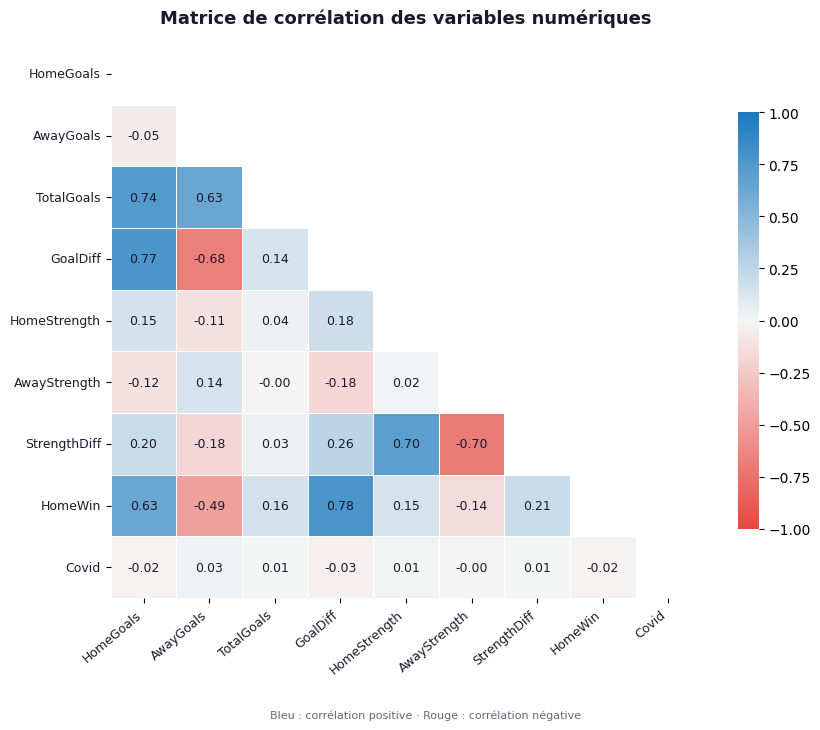

In [14]:
numeric_cols = ['HomeGoals','AwayGoals','TotalGoals','GoalDiff',
                'HomeStrength','AwayStrength','StrengthDiff','HomeWin','Covid']
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

# Palette bleue → blanc → rouge, lisible sur fond blanc
cmap = LinearSegmentedColormap.from_list('report', ['#e8473f','#f5f5f5','#1a7abf'], N=256)

fig, ax = plt.subplots(figsize=(9, 7.5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')
fig.subplots_adjust(top=0.92, bottom=0.18, left=0.15, right=0.97)

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', linewidths=0.5,
            cmap=cmap, vmin=-1, vmax=1, linecolor='white',
            ax=ax, annot_kws={'size':9, 'color':C['text']},
            cbar_kws={'shrink':0.75})

ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right',
                   color=C['text'], fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0,
                   color=C['text'], fontsize=9)
ax.set_title('Matrice de corrélation des variables numériques',
             fontsize=13, fontweight='bold', color=C['text'], pad=14)
fig.text(0.5, 0.02, 'Bleu : corrélation positive · Rouge : corrélation négative',
         ha='center', color=C['subtext'], fontsize=8)

plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_05_heatmap.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Les corrélations les plus fortes sont des artefacts de construction (GoalDiff/HomeWin à 0.78, GoalDiff/HomeGoals à 0.77). La corrélation analytiquement la plus intéressante est **StrengthDiff/HomeWin à 0.21** — positive mais modérée, confirmant qu'il existe une part d'avantage domicile non expliquée par le niveau des équipes. Covid est proche de 0 pour toutes les variables car seulement 2 saisons sur 30 sont concernées.

## 6 — Évolution des buts domicile vs extérieur
**Objectif :** observer si l'écart de buts entre domicile et extérieur évolue dans le temps.

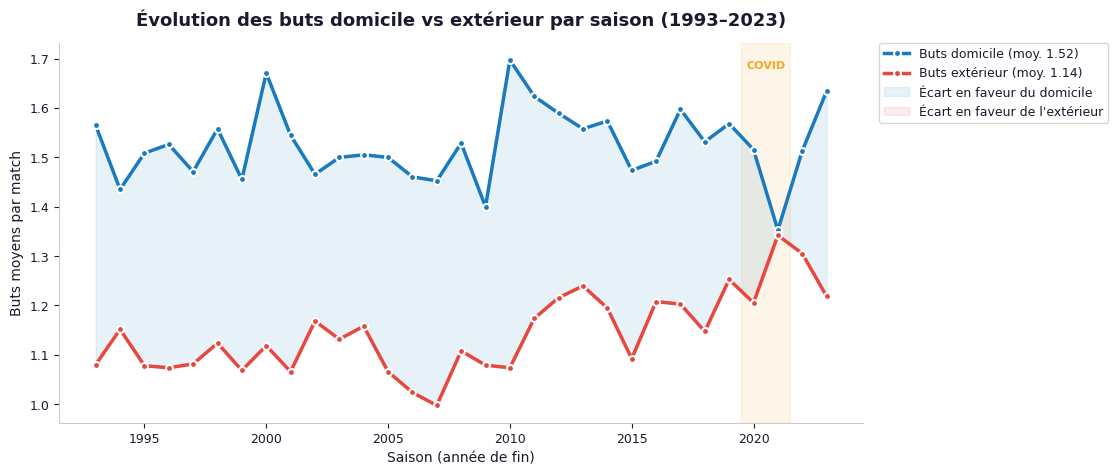

In [15]:
season_goals = df.groupby('Season_End_Year').agg(
    AvgHomeGoals=('HomeGoals','mean'),
    AvgAwayGoals=('AwayGoals','mean'),
).reset_index()

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.88, bottom=0.12, left=0.08, right=0.75)

# Zone Covid
ax.axvspan(2019.5, 2021.5, color=C['covid'], alpha=0.10, zorder=0)
ax.text(2020.5, 1.68, 'COVID', ha='center', fontsize=8,
        color=C['covid'], fontweight='bold')

# Courbes
ax.plot(season_goals['Season_End_Year'], season_goals['AvgHomeGoals'],
        color=C['home'], linewidth=2.5, marker='o', markersize=5,
        markerfacecolor=C['home'], markeredgecolor='white', markeredgewidth=1.5,
        label=f"Buts domicile (moy. {df['HomeGoals'].mean():.2f})", zorder=5)
ax.plot(season_goals['Season_End_Year'], season_goals['AvgAwayGoals'],
        color=C['away'], linewidth=2.5, marker='o', markersize=5,
        markerfacecolor=C['away'], markeredgecolor='white', markeredgewidth=1.5,
        label=f"Buts extérieur (moy. {df['AwayGoals'].mean():.2f})", zorder=5)

# Remplissage entre les courbes
ax.fill_between(season_goals['Season_End_Year'],
                season_goals['AvgHomeGoals'], season_goals['AvgAwayGoals'],
                where=season_goals['AvgHomeGoals'] >= season_goals['AvgAwayGoals'],
                alpha=0.10, color=C['home'], interpolate=True,
                label='Écart en faveur du domicile')
ax.fill_between(season_goals['Season_End_Year'],
                season_goals['AvgHomeGoals'], season_goals['AvgAwayGoals'],
                where=season_goals['AvgHomeGoals'] < season_goals['AvgAwayGoals'],
                alpha=0.10, color=C['away'], interpolate=True,
                label='Écart en faveur de l\'extérieur')

ax.set_title('Évolution des buts domicile vs extérieur par saison (1993–2023)',
             fontsize=13, fontweight='bold', color=C['text'], pad=12)
white_theme(ax, xlabel='Saison (année de fin)', ylabel='Buts moyens par match')
white_legend(ax, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_06_evolution_buts.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** La courbe bleue (domicile) est systématiquement au-dessus de la courbe rouge (extérieur). L'écart se réduit nettement pendant le Covid (0.41 → 0.16 but/match). On note aussi une légère tendance haussière des buts extérieurs depuis 2010, suggérant que le football moderne tend à réduire progressivement l'avantage domicile.

## 7 — Big Six : taux de victoire domicile vs extérieur
**Objectif :** vérifier que l'avantage domicile n'est pas limité aux petites équipes.

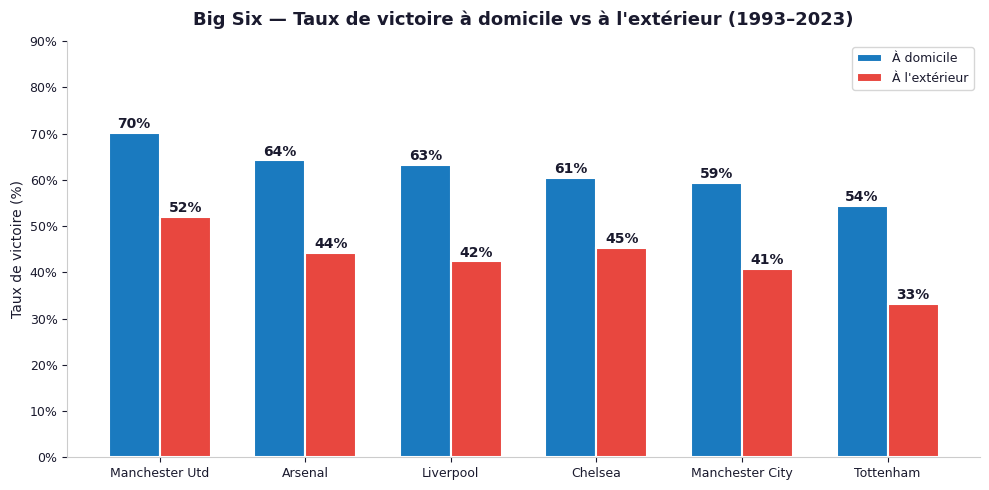

In [16]:
BIG_SIX = ['Arsenal','Chelsea','Liverpool','Manchester City','Manchester Utd','Tottenham']

big6_home = (df[df['HomeTeam'].isin(BIG_SIX)]
             .groupby('HomeTeam').agg(HomeWinRate=('HomeWin','mean'))
             .reset_index().rename(columns={'HomeTeam':'Team'}))
big6_away = (df[df['AwayTeam'].isin(BIG_SIX)]
             .groupby('AwayTeam').agg(AwayWinRate=('AwayWin','mean'))
             .reset_index().rename(columns={'AwayTeam':'Team'}))
big6 = big6_home.merge(big6_away, on='Team').sort_values('HomeWinRate', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('white')
fig.subplots_adjust(top=0.88, bottom=0.14, left=0.12, right=0.95)

x = np.arange(len(BIG_SIX))
w = 0.35
b1 = ax.bar(x - w/2, big6['HomeWinRate']*100, w,
            color=C['home'], label='À domicile', edgecolor='white', linewidth=1.5)
b2 = ax.bar(x + w/2, big6['AwayWinRate']*100, w,
            color=C['away'], label='À l\'extérieur', edgecolor='white', linewidth=1.5)
for bar in list(b1)+list(b2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
            f'{bar.get_height():.0f}%', ha='center', va='bottom',
            color=C['text'], fontweight='bold', fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(big6['Team'], fontsize=10, color=C['text'])
ax.set_ylim(0, 90)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Big Six — Taux de victoire à domicile vs à l\'extérieur (1993–2023)',
             fontsize=13, fontweight='bold', color=C['text'], pad=12)
white_theme(ax, ylabel='Taux de victoire (%)')
white_legend(ax, loc='upper right')

plt.tight_layout()
plt.savefig(ROOT / 'outputs' / 'figures' / 'FIG_07_big6.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

**Lecture :** Pour chacun des six clubs sans exception, la barre bleue est plus haute que la rouge. Manchester United affiche le taux domicile le plus élevé (70%), Tottenham le plus grand écart relatif (54% vs 33%). L'avantage domicile est **universel** — il touche tous les clubs, y compris les plus dominants.

---
## Conclusion

L'ensemble de cette analyse exploratoire converge vers une réponse claire : **jouer à domicile confère un avantage réel, structurel et universel** en Premier League.

Trois résultats clés le confirment :
1. **45,9%** de victoires à domicile sur 30 saisons, soit 12 points au-dessus de l'équilibre théorique
2. **−5 points** pendant le Covid (sans public), avec retour à la normale dès 2022 — argument causal fort
3. **32,2%** de victoires domicile même en Q1 (contexte très défavorable) — l'avantage persiste indépendamment du niveau des équipes

**Limite principale :** notre variable `StrengthDiff` ne capture pas des facteurs difficilement quantifiables comme la fatigue liée aux déplacements, les blessures, ou l'effet psychologique d'une série de défaites. Une régression logistique permettrait de formaliser et tester statistiquement ces résultats.